# A02 — Falta pré-processamento?

## Objetivo

A01 aplicou o pré-processamento original sem alterações. Este notebook
avalia, item por item, se algo mais deveria ser feito antes da integração —
**sem mudar a linha principal**. Cada item termina numa recomendação
(necessário / opcional / não necessário) apoiada num número.

## Itens avaliados

1. células de baixo conteúdo que passam no filtro;
2. RNA ambiente;
3. fração intrônica por célula (células danificadas);
4. contaminantes não-T;
5. universo de genes (a interseção entre bibliotecas);
6. composição dos genes variáveis (HVGs);
7. a biblioteca atípica CTH97_ML.

Doublets ficam em A03.

## Dados

* células e flags de A01; objetos por biblioteca de A01;
* matrizes brutas do Cell Ranger (gotas vazias → perfil ambiente);
* fração intrônica por barcode, de C03 (`molecule_info.h5`);
* anotação automática do Cell Ranger, só para separar T de não-T;
* listas de genes de C02 e C03.

## Decisões

* O perfil ambiente vem dos barcodes não chamados como célula com 1–100 UMIs,
  a faixa padrão do SoupX.
* A contaminação é estimada pelo método das células não expressoras: genes de
  imunoglobulina não são expressos por células T, então todo UMI de
  imunoglobulina numa célula T veio do ambiente.
* Nada aqui é anotação de subtipo T. Rótulos automáticos e marcadores de
  linhagem entram só para separar T de não-T.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from functions import config, fmt as F, io, pipeline as pl, plotting, qc
from functions.issues import IssueLog, show

sc.settings.verbosity = 0
plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "A02_preprocessamento_adicional"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
rec = []          # tabela final de recomendações


def recomenda(item, veredito, evidencia, acao):
    rec.append({"item": item, "veredito": veredito, "evidencia": evidencia, "acao": acao})

## Leitura única por biblioteca

In [2]:
celulas = io.load_data("A01_preprocessamento", "celulas_qc")
molbc = io.load_data("C03_rarefacao_citocinas", "mol_barcodes")
celulas = celulas.merge(molbc[["library_id", "barcode", "frac_intronica"]],
                        on=["library_id", "barcode"], how="left")
assert celulas["frac_intronica"].notna().all()

PANEL_AMB = ["IFNG", "TNF", "IL2", "IL17A", "IL17F", "IL22", "IL9", "IL4", "IL5", "IL10", "IL13", "IL21"]
amb_rows, percell, amb_prof, cyto_amb, top_amb = [], [], {}, [], {}
for lib in LIBS:
    amb = qc.ambient_profile(lib)
    cls_ref = pl.classify_genes(amb["gene_names"])
    a = ad.read_h5ad(io.data_path("A01_preprocessamento/new", lib, "h5ad"))
    sym = a.var["gene_symbols"].astype(str).to_numpy()
    cls = pl.classify_genes(sym)
    Xc = a.X.tocsc()
    tot = np.asarray(a.X.sum(axis=1)).ravel()
    ct = io.read_celltypes(lib).reindex(a.obs_names)
    is_t = (ct["coarse_cell_type"] == "T cell").to_numpy()

    def soma(classe):
        return np.asarray(Xc[:, np.flatnonzero((cls == classe).to_numpy())].sum(axis=1)).ravel()

    ig, hb, ribo, mt = soma("imunoglobulina"), soma("hemoglobina"), soma("ribossomal"), soma("mitocondrial")
    a_ig = amb["profile"][(cls_ref == "imunoglobulina").to_numpy()].sum() / amb["umis"]
    a_hb = amb["profile"][(cls_ref == "hemoglobina").to_numpy()].sum() / amb["umis"]
    e_ig = qc.contamination_from_markers(ig[is_t], tot[is_t], a_ig)
    e_hb = qc.contamination_from_markers(hb[is_t], tot[is_t], a_hb)

    # pseudobulk das células de baixo conteúdo × ambiente × demais
    idx = pd.Index(a.var_names).get_indexer(amb["gene_ids"])
    ok = idx >= 0

    def pseudobulk(mask):
        v = np.zeros(len(amb["gene_ids"]))
        v[ok] = np.asarray(a.X[mask].sum(axis=0)).ravel()[idx[ok]]
        return v

    baixo = tot < 1000
    cors = {}
    if baixo.sum() >= 20:
        L, C = pseudobulk(baixo), pseudobulk(~baixo)
        cors = {"cor_baixo_ambiente": qc.pseudobulk_correlation(L, amb["profile"].astype(float)),
                "cor_baixo_demais": qc.pseudobulk_correlation(L, C),
                "cor_ambiente_demais": qc.pseudobulk_correlation(amb["profile"].astype(float), C)}

    amb_rows.append({
        "library_id": lib, "celulas": a.n_obs,
        "umis_fora_de_celulas": amb["umis_fora_de_celulas"] / (amb["umis_fora_de_celulas"] + amb["umis_em_celulas"]),
        "gotas_vazias_1_100": amb["n_barcodes"], "umis_ambiente": amb["umis"],
        "fundo_100_499_umis": amb["fundo_100_499"], "fundo_500_mais": amb["fundo_500_mais"],
        "frac_ig_no_ambiente": a_ig, "umis_ig_ambiente": int(a_ig * amb["umis"]),
        "umis_ig_em_T": e_ig["umis_marcador_celulas"], "rho_ig": e_ig["rho"],
        "umis_hb_ambiente": int(a_hb * amb["umis"]), "umis_hb_em_T": e_hb["umis_marcador_celulas"],
        "rho_hb": e_hb["rho"], **cors,
    })
    percell.append(pd.DataFrame({
        "library_id": lib, "barcode": a.obs_names, "umis": tot,
        "azimuth_amplo": ct["coarse_cell_type"].to_numpy(), "azimuth_fino": ct["fine_cell_type"].to_numpy(),
        "umis_ig": ig, "umis_hb": hb, "frac_ribo": ribo / tot, "frac_mt": mt / tot,
        "pct_top50": a.obs["pct_counts_in_top_50_genes"].to_numpy(),
    }))
    amb_prof[lib] = pd.Series(amb["profile"] / amb["umis"], index=amb["gene_names"])
    top_amb[lib] = amb_prof[lib].sort_values(ascending=False).head(10)

    # citocinas: positivos de 1 UMI × esperado por RNA ambiente
    rho = e_ig["rho"]
    for gname in PANEL_AMB:
        j = np.flatnonzero(sym == gname)
        if not len(j):
            continue
        c = np.asarray(Xc[:, j[0]].todense()).ravel()
        a_g = float(amb["profile"][np.flatnonzero(amb["gene_names"] == gname)[0]] / amb["umis"])
        esperado = float((1 - np.exp(-rho * tot * a_g)).sum()) if np.isfinite(rho) else np.nan
        cyto_amb.append({"library_id": lib, "gene": gname, "positivas": int((c > 0).sum()),
                         "com_1_umi": int((c == 1).sum()), "com_3_ou_mais": int((c >= 3).sum()),
                         "frac_no_ambiente": a_g, "esperadas_por_ambiente": esperado})
    del a, Xc

amb_tab = pd.DataFrame(amb_rows).set_index("library_id")
pc = pd.concat(percell, ignore_index=True)
mant = celulas[celulas["mantida"]].merge(pc, on=["library_id", "barcode"], how="left")
assert len(mant) == len(pc) and mant["umis"].notna().all()
print(f"células mantidas por A01: {F.n(len(mant))} em {mant['library_id'].nunique()} bibliotecas")

células mantidas por A01: 35.064 em 14 bibliotecas


## 1. Células de baixo conteúdo

O Cell Ranger chama como célula qualquer barcode acima de ~500 UMIs que
difira do perfil ambiente. O filtro MAD é relativo a cada biblioteca; a
pergunta é quantas células de baixo conteúdo (menos de 1.000 UMIs) sobram
depois dele, e se elas se parecem com célula ou com gota vazia.

In [3]:
mant["baixo_conteudo"] = mant["total_counts"] < 1000
b1 = mant.groupby("library_id").agg(
    celulas=("barcode", "size"), baixo=("baixo_conteudo", "sum"),
    umis_medianos=("total_counts", "median")).reindex(LIBS)
b1["frac_baixo"] = b1["baixo"] / b1["celulas"]
com = b1.index[b1["baixo"] > 0].tolist()
linhas = []
for lib in com:
    q = mant[mant["library_id"] == lib]
    lo, hi = q[q["baixo_conteudo"]], q[~q["baixo_conteudo"]]
    linhas.append({
        "library_id": lib, "n_baixo": len(lo), "frac": len(lo) / len(q),
        "intronica_baixo": lo["frac_intronica"].median(), "intronica_demais": hi["frac_intronica"].median(),
        "mt_baixo": lo["pct_counts_mt"].median(), "mt_demais": hi["pct_counts_mt"].median(),
        "T_azimuth_baixo": (lo["azimuth_amplo"] == "T cell").mean(),
        "T_azimuth_demais": (hi["azimuth_amplo"] == "T cell").mean(),
        "cor_com_ambiente": amb_tab.loc[lib, "cor_baixo_ambiente"],
        "cor_com_demais_celulas": amb_tab.loc[lib, "cor_baixo_demais"],
        "cor_ambiente_com_celulas": amb_tab.loc[lib, "cor_ambiente_demais"],
    })
baixo_tab = pd.DataFrame(linhas).set_index("library_id")
io.save_table(b1.join(baixo_tab.drop(columns=["frac"])), NB, "celulas_de_baixo_conteudo",
              description="Células mantidas com menos de 1.000 UMIs, por biblioteca, e como se comparam às demais")

print(f"células mantidas com menos de 1.000 UMIs: {F.n(b1['baixo'].sum())} de {F.n(b1['celulas'].sum())} "
      f"({F.pct(b1['baixo'].sum() / b1['celulas'].sum())}), todas em {len(com)} bibliotecas: {com}")
F.styler(baixo_tab, {"n_baixo": F.n, "frac": F.pct, "intronica_baixo": F.pct, "intronica_demais": F.pct,
                     "mt_baixo": lambda v: F.f(v, 1) + "%", "mt_demais": lambda v: F.f(v, 1) + "%",
                     "T_azimuth_baixo": lambda v: F.pct(v, 0), "T_azimuth_demais": lambda v: F.pct(v, 0),
                     "cor_com_ambiente": lambda v: F.f(v, 2), "cor_com_demais_celulas": lambda v: F.f(v, 2),
                     "cor_ambiente_com_celulas": lambda v: F.f(v, 2)})

células mantidas com menos de 1.000 UMIs: 730 de 35.064 (2,1%), todas em 2 bibliotecas: ['CTH92_ML', 'CTH97_ML']


,n_baixo,frac,intronica_baixo,intronica_demais,mt_baixo,mt_demais,T_azimuth_baixo,T_azimuth_demais,cor_com_ambiente,cor_com_demais_celulas,cor_ambiente_com_celulas
library_id,,,,,,,,,,,
CTH92_ML,108,"7,1%","34,9%","33,5%","2,1%","2,5%",95%,98%,"0,59","0,79","0,85"
CTH97_ML,622,"13,2%","13,2%","7,2%","2,7%","1,8%",93%,94%,"0,85","0,91","0,94"


**Leitura.** Em 12 das 14 bibliotecas o filtro MAD já remove tudo abaixo de
1.000 UMIs: nelas o limiar relativo caiu acima desse valor. As células de
baixo conteúdo que restam estão nas duas bibliotecas de baixa complexidade
(C01), onde a mediana da biblioteca inteira é baixa. Nelas, as células de
baixo conteúdo são rotuladas como T na mesma proporção que as demais, e o
perfil agregado delas se parece mais com o das outras células da biblioteca
do que com o do ambiente — não são gotas vazias. São a cauda de uma
distribuição deslocada, não uma população à parte.

In [4]:
veredito = "opcional"
recomenda("células de baixo conteúdo (< 1.000 UMIs)", veredito,
          f"{F.n(b1['baixo'].sum())} células ({F.pct(b1['baixo'].sum() / b1['celulas'].sum())}), só em "
          f"{', '.join(com)}; perfil mais próximo das demais células (r = "
          f"{F.f(baixo_tab['cor_com_demais_celulas'].min(), 2)}–{F.f(baixo_tab['cor_com_demais_celulas'].max(), 2)}) "
          f"que do ambiente (r = {F.f(baixo_tab['cor_com_ambiente'].min(), 2)}–{F.f(baixo_tab['cor_com_ambiente'].max(), 2)})",
          "manter; conferir em A05 se formam cluster próprio e, se formarem, aplicar piso de 1.000 UMIs")

## 2. RNA ambiente

C01 mostrou cinco bibliotecas com alarme de baixa fração de reads em
células. A pergunta relevante para a análise não é quanto RNA está fora das
células, mas **quanto do conteúdo de cada célula veio de fora**.

In [5]:
amb_tab["confiavel_ig"] = (amb_tab["umis_ig_ambiente"] >= 500) & (amb_tab["umis_ig_em_T"] >= 20)
amb_tab["confiavel_hb"] = (amb_tab["umis_hb_ambiente"] >= 500) & (amb_tab["umis_hb_em_T"] >= 20)
io.save_table(amb_tab, NB, "rna_ambiente", description="RNA ambiente por biblioteca e contaminação estimada (ρ)")
F.styler(amb_tab[["celulas", "umis_fora_de_celulas", "gotas_vazias_1_100", "fundo_100_499_umis",
                  "frac_ig_no_ambiente", "umis_ig_ambiente", "umis_ig_em_T", "rho_ig",
                  "umis_hb_ambiente", "umis_hb_em_T", "rho_hb"]],
         {"celulas": F.n, "umis_fora_de_celulas": F.pct, "gotas_vazias_1_100": F.n,
          "fundo_100_499_umis": F.n, "frac_ig_no_ambiente": lambda v: F.pct(v, 2),
          "umis_ig_ambiente": F.n, "umis_ig_em_T": F.n, "rho_ig": lambda v: F.pct(v, 2),
          "umis_hb_ambiente": F.n, "umis_hb_em_T": F.n, "rho_hb": lambda v: F.pct(v, 2)})

,celulas,umis_fora_de_celulas,gotas_vazias_1_100,fundo_100_499_umis,frac_ig_no_ambiente,umis_ig_ambiente,umis_ig_em_T,rho_ig,umis_hb_ambiente,umis_hb_em_T,rho_hb
library_id,,,,,,,,,,,
CTH92_NS,809,"45,9%",1.496.071,107,"0,09%",6.534,43,"0,59%",3,0,"0,00%"
CTH92_ML,1.531,"43,0%",1.361.842,296,"0,05%",3.097,64,"1,62%",4,0,"0,00%"
CTH94_NS,5.576,"12,2%",1.659.169,2.915,"0,05%",4.834,304,"0,85%",8,0,"0,00%"
CTH94_ML,499,"44,2%",1.203.640,262,"0,26%",13.371,85,"0,53%",3,0,"0,00%"
CTH97_NS,1.513,"27,5%",1.265.183,5.238,"1,21%",60.101,1.512,"0,92%",18,0,"0,00%"
CTH97_ML,4.696,"15,2%",885.063,666,"0,68%",15.981,3.296,"3,25%",0,0,–
PB20_NS,592,"35,1%",1.039.520,103,"0,09%",3.183,67,"1,25%",4,0,"0,00%"
PB20_ML,777,"28,1%",1.071.785,147,"0,17%",6.089,33,"0,24%",2,0,"0,00%"
PB21_NS,3.665,"21,8%",1.551.379,21.533,"0,07%",4.681,128,"0,46%",5,0,"0,00%"


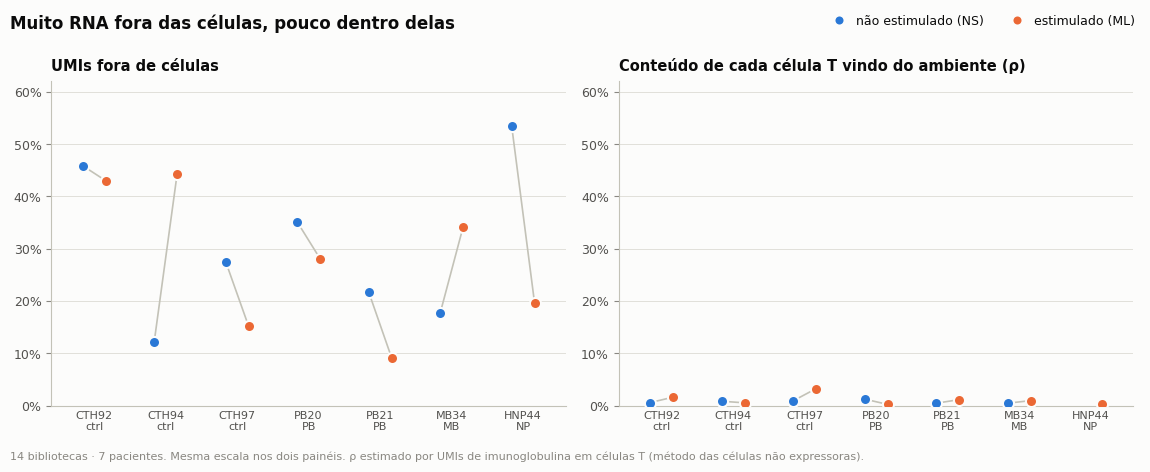

UMIs fora de células: 9% a 53%
contaminação por célula (ρ, imunoglobulina), 13 bibliotecas com estimativa confiável: 0,2% a 3,3% (mediana 0,8%); maior em CTH97_ML
estimativa independente por hemoglobina, onde há UMIs suficientes: HNP44_ML 0,4% (imunoglobulina: 0,4%)
Spearman entre UMIs fora de células e ρ (n=14, descritivo): -0,06

genes mais abundantes no ambiente (exemplo, CTH92_NS): RPS27, RPL10, RPL41, RPL13, RPL28, RPS12, RPL32, RPLP1


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
plotting.paired_dots(axes[0], amb_tab["umis_fora_de_celulas"])
plotting.percent(axes[0])
axes[0].set_ylim(0, 0.62)
axes[0].set_title("UMIs fora de células", fontsize=10.5)
plotting.paired_dots(axes[1], amb_tab["rho_ig"].where(amb_tab["confiavel_ig"]))
plotting.percent(axes[1], decimals=0)
axes[1].set_ylim(0, 0.62)
axes[1].set_title("Conteúdo de cada célula T vindo do ambiente (ρ)", fontsize=10.5)
for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plotting.stim_legend(fig, loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0))
fig.suptitle("Muito RNA fora das células, pouco dentro delas", x=0.01, y=0.985, ha="left",
             fontsize=12, fontweight="bold")
plotting.note(fig, f"{plotting.N_DESIGN}. Mesma escala nos dois painéis. ρ estimado por UMIs de "
                   "imunoglobulina em células T (método das células não expressoras).")
plotting.savefig(fig, NB, "rna_ambiente", description="UMIs fora de células e contaminação por célula (ρ)",
                 data=amb_tab[["umis_fora_de_celulas", "rho_ig", "confiavel_ig"]])
plt.show()

conf = amb_tab[amb_tab["confiavel_ig"]]
hb_ok = amb_tab[amb_tab["confiavel_hb"]]
print(f"UMIs fora de células: {F.pct(amb_tab['umis_fora_de_celulas'].min(), 0)} a "
      f"{F.pct(amb_tab['umis_fora_de_celulas'].max(), 0)}")
print(f"contaminação por célula (ρ, imunoglobulina), {len(conf)} bibliotecas com estimativa confiável: "
      f"{F.pct(conf['rho_ig'].min(), 1)} a {F.pct(conf['rho_ig'].max(), 1)} (mediana {F.pct(conf['rho_ig'].median(), 1)}); "
      f"maior em {conf['rho_ig'].idxmax()}")
if len(hb_ok):
    print("estimativa independente por hemoglobina, onde há UMIs suficientes: " +
          "; ".join(f"{l} {F.pct(r['rho_hb'], 1)} (imunoglobulina: {F.pct(r['rho_ig'], 1)})" for l, r in hb_ok.iterrows()))
rho_s = amb_tab["umis_fora_de_celulas"].corr(amb_tab["rho_ig"], method="spearman")
print(f"Spearman entre UMIs fora de células e ρ (n=14, descritivo): {F.f(rho_s, 2)}")
print("\ngenes mais abundantes no ambiente (exemplo, " + LIBS[0] + "): " + ", ".join(top_amb[LIBS[0]].index[:8]))

**Leitura.** Os dois painéis estão na mesma escala de propósito. Até metade
dos UMIs de uma biblioteca está fora das células, mas o que entra em cada
célula é da ordem de 1%. A explicação é aritmética: o RNA ambiente está
diluído em mais de um milhão de gotas vazias, com poucos UMIs cada, enquanto
uma célula tem milhares de UMIs próprios. O alarme do Cell Ranger nas
bibliotecas com poucas células reflete poucas células, não células sujas.

In [7]:
cy = pd.DataFrame(cyto_amb)
foco = cy[cy["com_1_umi"] >= 10].copy()
foco["razao_esperado_observado"] = foco["esperadas_por_ambiente"] / foco["com_1_umi"]
foco = foco.sort_values("com_1_umi", ascending=False)
io.save_table(cy, NB, "citocinas_e_rna_ambiente",
              description="Células positivas com 1 UMI por citocina × número esperado por RNA ambiente", index=False)
print("combinações biblioteca × citocina com ≥ 10 células de exatamente 1 UMI:")
F.styler(foco.head(18).set_index(["library_id", "gene"])[["positivas", "com_1_umi", "com_3_ou_mais",
                                                           "frac_no_ambiente", "esperadas_por_ambiente",
                                                           "razao_esperado_observado"]],
         {"positivas": F.n, "com_1_umi": F.n, "com_3_ou_mais": F.n,
          "frac_no_ambiente": lambda v: f"{v * 1e6:,.0f} por milhão".replace(",", "."),
          "esperadas_por_ambiente": lambda v: F.f(v, 1), "razao_esperado_observado": lambda v: F.pct(v, 0)})

combinações biblioteca × citocina com ≥ 10 células de exatamente 1 UMI:


In [8]:
tot_obs, tot_esp = foco["com_1_umi"].sum(), foco["esperadas_por_ambiente"].sum()
c97 = foco[foco["library_id"] == "CTH97_ML"]
print(f"nessas combinações: {F.n(tot_obs)} células com 1 UMI; esperadas por RNA ambiente: {F.f(tot_esp, 0)} "
      f"({F.pct(tot_esp / tot_obs, 0)})")
if len(c97):
    print("CTH97_ML: " + "; ".join(
        f"{r['gene']} {F.n(r['com_1_umi'])} com 1 UMI, {F.f(r['esperadas_por_ambiente'], 0)} esperadas "
        f"({F.pct(r['razao_esperado_observado'], 0)})" for _, r in c97.iterrows()))
alto = foco[(foco["razao_esperado_observado"] >= 0.25)]
print("combinações em que o ambiente explica ≥ 25% das células com 1 UMI: "
      + "; ".join(f"{r['library_id']} {r['gene']}" for _, r in alto.iterrows()))

nessas combinações: 3.271 células com 1 UMI; esperadas por RNA ambiente: 590 (18%)
CTH97_ML: IFNG 339 com 1 UMI, 186 esperadas (55%); TNF 245 com 1 UMI, 11 esperadas (5%); IL17F 207 com 1 UMI, 118 esperadas (57%); IL22 160 com 1 UMI, 132 esperadas (83%); IL9 72 com 1 UMI, 58 esperadas (81%); IL17A 16 com 1 UMI, 10 esperadas (63%); IL21 12 com 1 UMI, 0 esperadas (0%)
combinações em que o ambiente explica ≥ 25% das células com 1 UMI: CTH97_ML IFNG; CTH97_ML IL17F; CTH97_ML IL22; PB21_ML IFNG; CTH97_ML IL9; PB21_ML IL2; CTH97_ML IL17A


**Leitura.** Para as citocinas a contaminação baixa ainda importa, porque o
que está em jogo são eventos de 1 UMI. Em CTH97_ML, onde algumas células
expressam IFNG, IL17F, IL22 e IL9 em dezenas de UMIs, esses transcritos
também estão no ambiente, e o número de células que receberiam 1 UMI deles
por acaso é mais da metade das células "positivas com 1 UMI" observadas.
Fora dessa situação — TNF, IL5 e as demais bibliotecas — o RNA ambiente
explica pouco.

Somado ao suporte de reads (C03), o critério prático para citocinas é
conservador: contar como positiva a célula com **2 UMIs ou mais**, e sempre
por biblioteca.

In [9]:
log.add("INFO", "RNA ambiente",
        "[verificado] apesar dos alarmes de baixa fração de reads em células, a contaminação por célula é baixa",
        evidence=f"UMIs fora de células de {F.pct(amb_tab['umis_fora_de_celulas'].min(), 0)} a "
                 f"{F.pct(amb_tab['umis_fora_de_celulas'].max(), 0)}; contaminação por célula T (ρ) de "
                 f"{F.pct(conf['rho_ig'].min(), 1)} a {F.pct(conf['rho_ig'].max(), 1)} (mediana "
                 f"{F.pct(conf['rho_ig'].median(), 1)}) em {len(conf)} bibliotecas com estimativa confiável",
        impact="correção de RNA ambiente mudaria pouco a matriz; o efeito relevante é sobre "
               "detecções de 1 UMI de genes muito expressos por outras células da mesma biblioteca",
        recommendation="não é necessário corrigir RNA ambiente para clustering; para citocinas, "
                       "não aceitar 1 UMI como positividade na biblioteca em que o gene é abundante")
recomenda("RNA ambiente", "não necessário",
          f"ρ de {F.pct(conf['rho_ig'].min(), 1)} a {F.pct(conf['rho_ig'].max(), 1)} por célula T "
          f"(mediana {F.pct(conf['rho_ig'].median(), 1)})",
          "sem correção para a integração; cautela com eventos de 1 UMI de citocinas (ver C03)")

## 3. Fração intrônica: células danificadas

RNA maduro é exônico; RNA nuclear tem íntrons. Uma gota com RNA ambiente
(citoplasma de células rompidas) tem fração intrônica baixa; uma célula que
perdeu o citoplasma e ficou só com o núcleo tem fração intrônica alta e
poucos UMIs. C01 apontou íntrons e antisense elevados em parte das
bibliotecas, e um "ombro" de barcodes com 100–500 UMIs no fundo.

In [10]:
it = mant.groupby("library_id")["frac_intronica"].describe(percentiles=[.01, .25, .5, .75, .99]).reindex(LIBS)
it["rho_intronica_umis"] = mant.groupby("library_id").apply(
    lambda q: q["frac_intronica"].corr(np.log(q["total_counts"]), method="spearman"))
med = mant.groupby("library_id")["frac_intronica"].transform("median")
mad = mant.groupby("library_id")["frac_intronica"].transform(lambda s: (s - s.median()).abs().median())
mant["intronica_alta"] = (mant["frac_intronica"] - med) > 5 * mad
it["frac_intronica_alta"] = mant.groupby("library_id")["intronica_alta"].mean()

# barcodes de fundo com 100–499 moléculas: o "ombro" do barcode rank
molbc["reads_por_molecula"] = molbc["reads"] / molbc["moleculas"]
ombro = molbc[(~molbc["celula"]) & (molbc["moleculas"] >= 100) & (molbc["moleculas"] < 500)].copy()
ombro["tipo_nucleo"] = ombro["frac_intronica"] >= 0.5
cel_mb = molbc[molbc["celula"]]
nuc = pd.DataFrame({
    "celulas_cellranger": cel_mb.groupby("library_id").size(),
    "fundo_100_499": ombro.groupby("library_id").size(),
    "fundo_intronica_mediana": ombro.groupby("library_id")["frac_intronica"].median(),
    "tipo_nucleo": ombro.groupby("library_id")["tipo_nucleo"].sum(),
    "tipo_nucleo_moleculas": ombro[ombro["tipo_nucleo"]].groupby("library_id")["moleculas"].median(),
    "tipo_nucleo_reads_por_molecula": ombro[ombro["tipo_nucleo"]].groupby("library_id")["reads_por_molecula"].median(),
    "celulas_reads_por_molecula": cel_mb.groupby("library_id")["reads_por_molecula"].median(),
    "celulas_intronica_mediana": cel_mb.groupby("library_id")["frac_intronica"].median(),
}).reindex(LIBS).fillna({"fundo_100_499": 0, "tipo_nucleo": 0})
nuc["tipo_nucleo_por_celula"] = nuc["tipo_nucleo"] / nuc["celulas_cellranger"]
io.save_table(it.join(nuc), NB, "fracao_intronica",
              description="Fração intrônica das células mantidas e barcodes de fundo de perfil nuclear")
io.save_data(nuc.reset_index(), NB, "barcodes_tipo_nucleo",
             description="Barcodes de fundo com 100–499 moléculas e fração intrônica ≥ 50%, por biblioteca")
F.styler(nuc[["celulas_cellranger", "celulas_intronica_mediana", "fundo_100_499", "fundo_intronica_mediana",
              "tipo_nucleo", "tipo_nucleo_por_celula", "tipo_nucleo_moleculas",
              "tipo_nucleo_reads_por_molecula", "celulas_reads_por_molecula"]],
         {"celulas_cellranger": F.n, "celulas_intronica_mediana": lambda v: F.pct(v, 0), "fundo_100_499": F.n,
          "fundo_intronica_mediana": lambda v: F.pct(v, 0), "tipo_nucleo": F.n,
          "tipo_nucleo_por_celula": lambda v: F.f(v, 2), "tipo_nucleo_moleculas": F.n,
          "tipo_nucleo_reads_por_molecula": lambda v: F.f(v, 1), "celulas_reads_por_molecula": lambda v: F.f(v, 1)})

,celulas_cellranger,celulas_intronica_mediana,fundo_100_499,fundo_intronica_mediana,tipo_nucleo,tipo_nucleo_por_celula,tipo_nucleo_moleculas,tipo_nucleo_reads_por_molecula,celulas_reads_por_molecula
library_id,,,,,,,,,
CTH92_NS,851,31%,107,19%,7,"0,01",229,"3,9","80,6"
CTH92_ML,1.570,34%,296,9%,3,"0,00",197,"92,6","89,4"
CTH94_NS,6.090,39%,2.915,27%,46,"0,01",199,"20,5","21,2"
CTH94_ML,547,31%,262,5%,0,"0,00",–,–,"97,4"
CTH97_NS,1.628,23%,5.238,64%,4.873,"2,99",126,"13,4","68,0"
CTH97_ML,4.737,8%,666,18%,5,"0,00",201,"18,3","75,1"
PB20_NS,635,18%,103,29%,8,"0,01",213,"32,1","134,3"
PB20_ML,841,18%,147,20%,8,"0,01",231,"27,7","94,5"
PB21_NS,4.266,22%,21.533,71%,21.097,"4,95",199,"3,3","19,1"


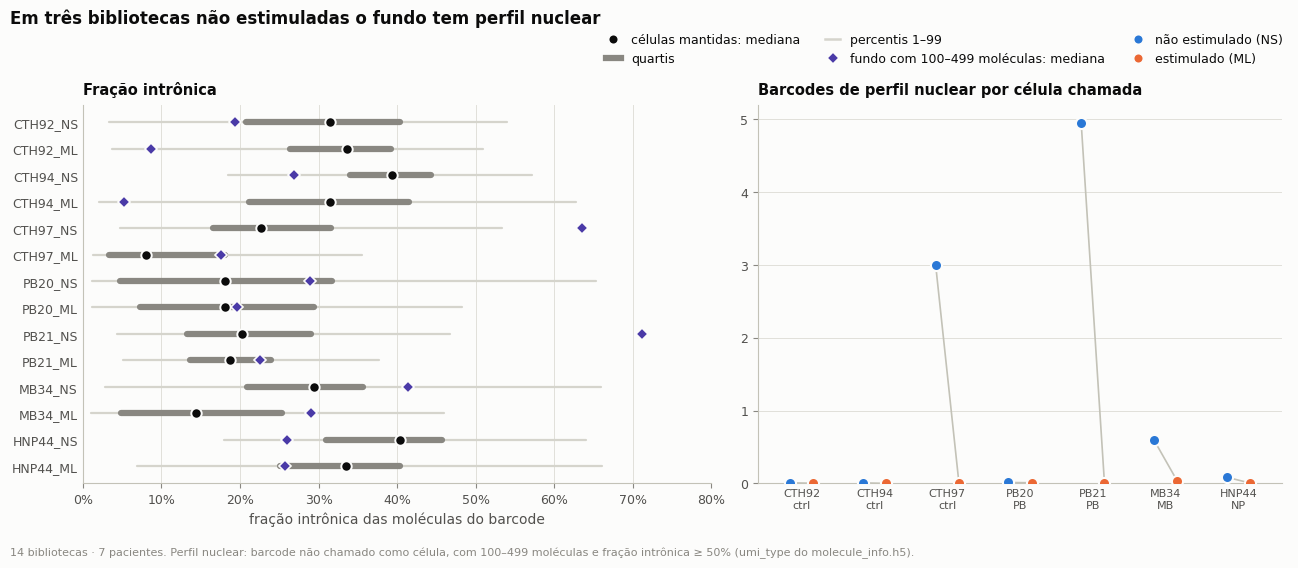

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
y = np.arange(len(LIBS))[::-1]
for yi, lib in zip(y, LIBS):
    r = it.loc[lib]
    ax.plot([r["1%"], r["99%"]], [yi, yi], color=plotting.CONTEXT, lw=1.6, zorder=1, solid_capstyle="round")
    ax.plot([r["25%"], r["75%"]], [yi, yi], color=INK["muted"], lw=4.5, zorder=2, solid_capstyle="round")
    ax.plot(r["50%"], yi, "o", ms=7.5, mfc=INK["primary"], mec=INK["surface"], mew=1.4, zorder=4)
    if nuc.loc[lib, "fundo_100_499"] >= 50:
        ax.plot(nuc.loc[lib, "fundo_intronica_mediana"], yi, marker="D", ms=6.5, mfc=plotting.CATEGORICAL[6],
                mec=INK["surface"], mew=1.2, zorder=3, ls="")
ax.set_yticks(y)
ax.set_yticklabels(LIBS)
ax.set_xlim(0, 0.8)
plotting.percent(ax, "x")
ax.set_xlabel("fração intrônica das moléculas do barcode")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("Fração intrônica", fontsize=10.5)
handles = [
    mpl.lines.Line2D([], [], marker="o", ls="", ms=7, mfc=INK["primary"], mec=INK["surface"], mew=1.2, label="células mantidas: mediana"),
    mpl.lines.Line2D([], [], color=INK["muted"], lw=4.5, label="quartis"),
    mpl.lines.Line2D([], [], color=plotting.CONTEXT, lw=1.8, label="percentis 1–99"),
    mpl.lines.Line2D([], [], marker="D", ls="", ms=6, mfc=plotting.CATEGORICAL[6], mec=INK["surface"], mew=1.2,
                     label="fundo com 100–499 moléculas: mediana"),
]
plotting.paired_dots(axes[1], nuc["tipo_nucleo_por_celula"])
axes[1].set_ylim(0, None)
plotting.decimals(axes[1], "y", 0)
axes[1].set_title("Barcodes de perfil nuclear por célula chamada", fontsize=10.5)
axes[1].tick_params(axis="x", labelsize=8)
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.legend(handles=handles + plotting.stim_handles(), loc="upper right", ncol=3, bbox_to_anchor=(0.995, 0.955))
fig.suptitle("Em três bibliotecas não estimuladas o fundo tem perfil nuclear", x=0.01, y=0.985, ha="left",
             fontsize=12, fontweight="bold")
plotting.note(fig, f"{plotting.N_DESIGN}. Perfil nuclear: barcode não chamado como célula, com 100–499 moléculas e "
                   "fração intrônica ≥ 50% (umi_type do molecule_info.h5).")
plotting.savefig(fig, NB, "fracao_intronica", description="Fração intrônica de células e fundo; barcodes de perfil nuclear",
                 data=nuc)
plt.show()

In [12]:
# O que há nesses barcodes: perfil agregado nas bibliotecas em que eles são muitos
muitas = nuc.index[nuc["tipo_nucleo"] >= 1000].tolist()
linhas_n = []
for lib in muitas:
    raw = io.read_raw(lib)
    pos = pd.Index(raw["barcodes"])
    alvo = ombro[(ombro["library_id"] == lib) & ombro["tipo_nucleo"]]["barcode"]
    cel = set(io.read_filtered(lib)["barcodes"])
    v_n = np.asarray(raw["X"][pos.get_indexer(alvo)].sum(axis=0)).ravel()
    v_c = np.asarray(raw["X"][pos.get_indexer(sorted(cel))].sum(axis=0)).ravel()
    nomes_g = raw["gene_names"]
    ti = list(io.gene_index(nomes_g, config.MARKERS_T).values())
    linhas_n.append({
        "library_id": lib, "barcodes": len(alvo),
        "correlacao_com_celulas": qc.pseudobulk_correlation(v_n.astype(float), v_c.astype(float)),
        "correlacao_com_ambiente": qc.pseudobulk_correlation(
            v_n.astype(float), (amb_prof[lib].to_numpy() * 1e6)),
        "frac_marcadores_T_nucleo": v_n[ti].sum() / v_n.sum(),
        "frac_marcadores_T_celulas": v_c[ti].sum() / v_c.sum(),
        "frac_mt_nucleo": v_n[np.char.startswith(nomes_g.astype(str), "MT-")].sum() / v_n.sum(),
        "frac_mt_celulas": v_c[np.char.startswith(nomes_g.astype(str), "MT-")].sum() / v_c.sum(),
        "genes_no_topo": ", ".join(nomes_g[np.argsort(-v_n)[:10]]),
    })
    del raw
perfil_n = pd.DataFrame(linhas_n).set_index("library_id")
io.save_table(perfil_n, NB, "barcodes_tipo_nucleo_perfil",
              description="Perfil agregado dos barcodes de fundo de perfil nuclear")
for lib, r in perfil_n.iterrows():
    print(f"{lib}: {F.n(r['barcodes'])} barcodes; marcadores de T = {F.pct(r['frac_marcadores_T_nucleo'], 2)} dos UMIs "
          f"(células: {F.pct(r['frac_marcadores_T_celulas'], 2)}); mitocondrial {F.pct(r['frac_mt_nucleo'])} "
          f"(células: {F.pct(r['frac_mt_celulas'])}); r com células {F.f(r['correlacao_com_celulas'], 2)}")
    print(f"   genes no topo: {r['genes_no_topo']}")

print(f"\nfração intrônica mediana das células mantidas: {F.pct(it['50%'].min(), 0)} ({it['50%'].idxmin()}) a "
      f"{F.pct(it['50%'].max(), 0)} ({it['50%'].idxmax()})")
print(f"células mantidas com fração intrônica > mediana + 5·MAD da própria biblioteca: "
      f"{F.n(mant['intronica_alta'].sum())} ({F.pct(mant['intronica_alta'].mean())})")
print(f"barcodes de perfil nuclear: {F.n(nuc['tipo_nucleo'].sum())} no total; "
      + "; ".join(f"{l} {F.n(nuc.loc[l, 'tipo_nucleo'])} ({F.f(nuc.loc[l, 'tipo_nucleo_por_celula'], 1)} por célula)"
                  for l in muitas)
      + f"; nas outras {len(LIBS) - len(muitas)} bibliotecas, no máximo "
        f"{F.n(nuc.drop(index=muitas)['tipo_nucleo'].max())}")

CTH97_NS: 4.873 barcodes; marcadores de T = 0,15% dos UMIs (células: 0,28%); mitocondrial 1,6% (células: 4,0%); r com células 0,58
   genes no topo: SLC26A3, STEAP1B, FOXP1, GPM6A, SYNE1, ZNF385D, LMOD3, PCDH11Y, ENSG00000287092, MCTP1
PB21_NS: 21.097 barcodes; marcadores de T = 0,09% dos UMIs (células: 0,31%); mitocondrial 0,9% (células: 3,8%); r com células 0,66
   genes no topo: SLC26A3, FOXP1, STEAP1B, GPM6A, SYNE1, ZNF385D, LMOD3, PCDH11Y, ENSG00000287092, MCTP1
MB34_NS: 1.289 barcodes; marcadores de T = 0,20% dos UMIs (células: 0,26%); mitocondrial 0,7% (células: 1,6%); r com células 0,69
   genes no topo: SLC26A3, STEAP1B, FOXP1, MALAT1, GPM6A, RPS27, SYNE1, ZNF385D, RPL13, RPS12

fração intrônica mediana das células mantidas: 8% (CTH97_ML) a 40% (HNP44_NS)
células mantidas com fração intrônica > mediana + 5·MAD da própria biblioteca: 160 (0,5%)
barcodes de perfil nuclear: 27.396 no total; CTH97_NS 4.873 (3,0 por célula); PB21_NS 21.097 (4,9 por célula); MB34_NS 1.289 (0,6 por c

**Leitura.** Duas coisas distintas.

*Dentro do objeto, nada a remover.* Entre as células mantidas, a fração
intrônica varia muito de biblioteca para biblioteca, mas dentro de cada uma a
distribuição é compacta e quase nenhuma célula destoa. Não há subpopulação
de células danificadas no que passou pelo filtro. A diferença entre
bibliotecas é efeito de lote da preparação.

*Fora do objeto, um sinal sobre a qualidade da amostra.* Em três bibliotecas
— todas não estimuladas — o "ombro" do barcode rank é formado por barcodes
com 100–500 moléculas das quais a maioria é intrônica. O perfil agregado
deles não é o de uma célula nem o do RNA ambiente: tem menos transcritos de
célula T e menos RNA mitocondrial que as células, e os genes no topo são os
mesmos nas três bibliotecas — justamente os que C03 identificou como
sustentados por reads intrônicos isolados (SLC26A3, STEAP1B, GPM6A,
ZNF385D, LMOD3, PCDH11Y; este último um gene do Y em bibliotecas que
incluem uma doadora). Um conjunto de regiões genômicas que se repete entre
pacientes, com pouco RNA de célula junto, é o perfil de **material nuclear
de células mortas** — núcleos ou cromatina sem citoplasma —, não de
expressão.

Esses barcodes não estão no objeto (o Cell Ranger não os chama como célula),
então não pedem filtro. Mas onde aparecem são mais numerosos que as próprias
células: naquelas suspensões havia mais células mortas do que vivas. Isso
volta em A03, na discussão da recuperação de células, e explica de onde vêm
os genes de reads isolados que contaminam as células dessas bibliotecas.

In [13]:
log.add("MAJOR", "barcodes de fundo com perfil nuclear",
        "em três bibliotecas não estimuladas há mais barcodes com material nuclear de células mortas do que células",
        evidence="; ".join(f"{l}: {F.n(nuc.loc[l, 'tipo_nucleo'])} barcodes com 100–499 moléculas e ≥ 50% "
                           f"intrônicas contra {F.n(nuc.loc[l, 'celulas_cellranger'])} células "
                           f"({F.f(nuc.loc[l, 'tipo_nucleo_por_celula'], 1)}×)" for l in muitas)
                 + f"; nas demais bibliotecas, no máximo {F.n(nuc.drop(index=muitas)['tipo_nucleo'].max())}"
                 + f"; genes no topo, iguais nas três: {perfil_n['genes_no_topo'].iloc[0]}",
        impact="indica morte celular extensa antes da captura nessas amostras; esses barcodes não "
               "entram no objeto, mas o material nuclear liberado contamina as células da "
               "biblioteca (os genes de reads intrônicos isolados de C03)",
        recommendation="registrar viabilidade antes do carregamento; considerar remoção de células "
                       "mortas na preparação; não usar --force-cells para 'recuperar' esses barcodes")
recomenda("fração intrônica (células danificadas no objeto)", "não necessário",
          f"só {F.pct(mant['intronica_alta'].mean())} das células mantidas acima de mediana + 5·MAD da própria "
          f"biblioteca; a variação é entre bibliotecas ({F.pct(it['50%'].min(), 0)}–{F.pct(it['50%'].max(), 0)})",
          "sem filtro adicional; os barcodes de perfil nuclear já ficam fora pela chamada do Cell Ranger")

## 4. Contaminantes não-T

In [14]:
nt = mant.assign(nao_T=mant["azimuth_amplo"] != "T cell")
tipos = pd.crosstab(nt["library_id"], nt["azimuth_amplo"]).reindex(LIBS)
ordem_tipos = tipos.sum().sort_values(ascending=False).index
nao_t = pd.DataFrame({"celulas": tipos.sum(axis=1), "nao_T": nt.groupby("library_id")["nao_T"].sum().reindex(LIBS)})
nao_t["frac_nao_T"] = nao_t["nao_T"] / nao_t["celulas"]
io.save_table(tipos[ordem_tipos], NB, "tipos_amplos_azimuth",
              description="Células mantidas por tipo amplo (anotação automática do Cell Ranger)")
print(f"células mantidas não rotuladas como T: {F.n(nao_t['nao_T'].sum())} de {F.n(nao_t['celulas'].sum())} "
      f"({F.pct(nao_t['nao_T'].sum() / nao_t['celulas'].sum())}); por biblioteca de "
      f"{F.pct(nao_t['frac_nao_T'].min())} a {F.pct(nao_t['frac_nao_T'].max())}")
print("tipos mais frequentes: " + "; ".join(f"{t} {F.n(n)}" for t, n in tipos.sum().sort_values(ascending=False).head(6).items()))

células mantidas não rotuladas como T: 1.236 de 35.064 (3,5%); por biblioteca de 1,7% a 6,8%
tipos mais frequentes: T cell 33.828; Coarse Not Confidently Annotated 719; B cell 328; NK cell 57; Cycling T/NK cell 29; Monocyte 23


In [15]:
recomenda("contaminantes não-T", "necessário, na etapa de anotação",
          f"{F.pct(nao_t['nao_T'].sum() / nao_t['celulas'].sum())} das células mantidas não são rotuladas "
          f"como T pela anotação automática (até {F.pct(nao_t['frac_nao_T'].max())} em {nao_t['frac_nao_T'].idxmax()})",
          "remover não-T depois do clustering, como no fluxo anterior; fora do escopo desta etapa")

## 5. Universo de genes

O original filtra genes **por amostra** (`min_cells=1`) e depois concatena
com `join="inner"`: um gene só sobrevive se for detectado em todas as 14
bibliotecas. A tabela de detecção por biblioteca vem de A01, com as células
que de fato passaram no filtro.

In [16]:
det = io.load_data("A01_preprocessamento", "genes_por_biblioteca").set_index("gene_id")
P = det[LIBS] > 0
total_cel = det[LIBS].sum(axis=1)
inter, uniao = P.all(axis=1), P.any(axis=1)
n_cel = celulas[celulas["passou_mad"]].groupby("library_id").size().reindex(LIBS)

loo = pd.DataFrame({
    "celulas": n_cel, "genes_detectados": P.sum(),
    "intersecao_sem_ela": [int(P.drop(columns=l).all(axis=1).sum()) for l in LIBS]}, index=LIBS)
loo["ausentes_so_nela"] = loo["intersecao_sem_ela"] - int(inter.sum())
perdidos = uniao & ~inter
regras = pd.DataFrame([
    {"regra": "interseção das 14 (original)", "genes": int(inter.sum())},
    {"regra": f"interseção sem {loo['ausentes_so_nela'].idxmax()}", "genes": int(loo["intersecao_sem_ela"].max())},
    {"regra": "união + ≥ 3 células no conjunto", "genes": int((total_cel >= 3).sum())},
    {"regra": "união + ≥ 10 células no conjunto", "genes": int((total_cel >= 10).sum())},
    {"regra": "união (≥ 1 célula)", "genes": int(uniao.sum())},
]).set_index("regra")

sym = det["gene_name"]
painel = config.CYTOKINES + config.PREVIOUSLY_MISSING[7:] + ["XIST"]
st_rows = []
for gname in painel:
    gid = sym.index[sym == gname]
    if not len(gid):
        continue
    gid = gid[0]
    st_rows.append({"gene": gname, "celulas_positivas": int(total_cel[gid]), "bibliotecas_com_deteccao": int(P.loc[gid].sum()),
                    "na_intersecao": bool(inter[gid]),
                    "na_intersecao_sem_a_menor": bool(P.drop(columns=loo["ausentes_so_nela"].idxmax()).loc[gid].all()),
                    "na_uniao_min3": bool(total_cel[gid] >= 3),
                    "zerado_em": ", ".join(l for l in LIBS if not P.loc[gid, l])})
status = pd.DataFrame(st_rows).set_index("gene")
cit_status = status.loc[[gname for gname in config.CYTOKINES if gname in status.index]]
regras["citocinas_perdidas"] = [
    int((~cit_status["na_intersecao"]).sum()), int((~cit_status["na_intersecao_sem_a_menor"]).sum()),
    int((~cit_status["na_uniao_min3"]).sum()), int((cit_status["celulas_positivas"] < 10).sum()),
    int((cit_status["celulas_positivas"] < 1).sum())]
io.save_table(regras, NB, "universo_de_genes_regras", description="Genes mantidos sob cada regra de junção")
io.save_table(loo, NB, "universo_de_genes_por_biblioteca", description="Quanto cada biblioteca limita a interseção")
io.save_table(status, NB, "universo_de_genes_painel", description="Citocinas e outros genes do painel sob cada regra")

print(f"união: {F.n(uniao.sum())} genes | interseção: {F.n(inter.sum())} | perdidos pela interseção: "
      f"{F.n(perdidos.sum())} ({F.pct(perdidos.sum() / uniao.sum(), 0)} da união)")
F.styler(regras, {"genes": F.n, "citocinas_perdidas": F.n})

união: 33.836 genes | interseção: 18.852 | perdidos pela interseção: 14.984 (44% da união)


,genes,citocinas_perdidas
regra,,
interseção das 14 (original),18.852,12
interseção sem HNP44_NS,19.982,12
união + ≥ 3 células no conjunto,31.765,1
união + ≥ 10 células no conjunto,28.693,1
união (≥ 1 célula),33.836,0


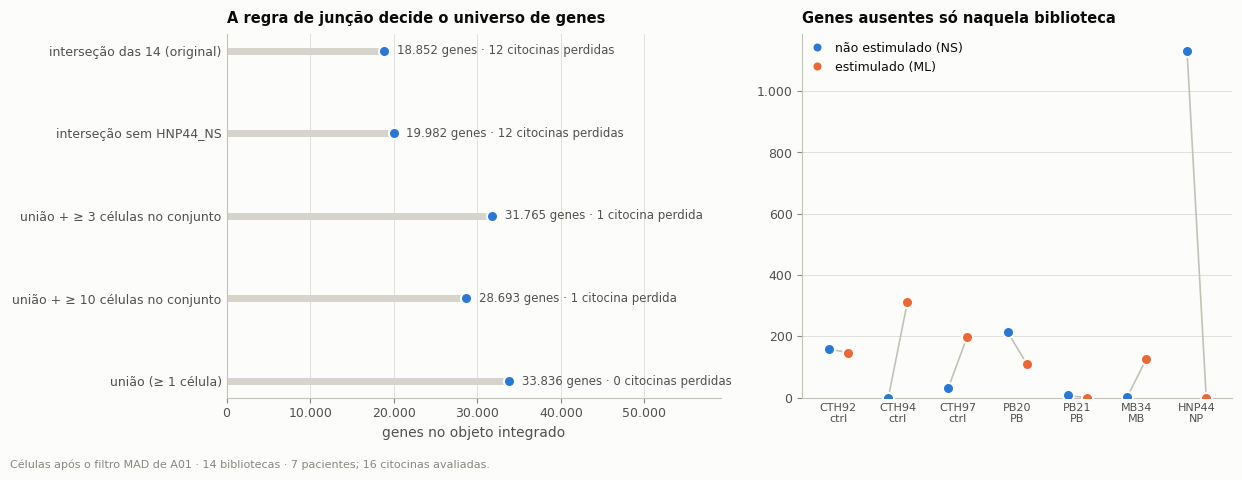

maior limitante individual: HNP44_NS (88 células), única biblioteca em que 1.130 genes estão ausentes = 8% dos 14.984 genes perdidos
os genes perdidos são detectados, em mediana, em 20 células; 4.240 deles em ≥ 50 células
citocinas perdidas pela interseção: 12 de 16 — IL2, IL4, IL9, IL10, IL13, IL17A, IL17F, IL21, IL22, CSF2, IL31, IL3
voltam ao remover HNP44_NS: nenhuma
XIST: fora da interseção (zerado em CTH97_NS, CTH97_ML; 16.401 células positivas)


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
yr = np.arange(len(regras))[::-1]
ax.hlines(yr, 0, regras["genes"], color=plotting.CONTEXT, lw=5, zorder=1)
ax.plot(regras["genes"], yr, "o", ms=8, mfc=plotting.ACCENT, mec=INK["surface"], mew=1.5, zorder=3, ls="")
for yi, (_, r) in zip(yr, regras.iterrows()):
    nc = int(r["citocinas_perdidas"])
    ax.annotate(f"{F.n(r['genes'])} genes · {nc} citocina{'s' if nc != 1 else ''} perdida{'s' if nc != 1 else ''}",
                (r["genes"], yi), textcoords="offset points", xytext=(9, 0), va="center",
                fontsize=8.5, color=INK["secondary"])
ax.set_yticks(yr)
ax.set_yticklabels(regras.index)
ax.set_xlim(0, regras["genes"].max() * 1.75)
plotting.thousands(ax, "x")
ax.set_xlabel("genes no objeto integrado")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("A regra de junção decide o universo de genes", fontsize=10.5)
plotting.paired_dots(axes[1], loo["ausentes_so_nela"])
plotting.thousands(axes[1])
axes[1].set_ylim(0, None)
axes[1].set_title("Genes ausentes só naquela biblioteca", fontsize=10.5)
axes[1].tick_params(axis="x", labelsize=8)
plotting.stim_legend(axes[1], loc="upper left")
fig.tight_layout()
plotting.note(fig, f"Células após o filtro MAD de A01 · {plotting.N_DESIGN}; {len(cit_status)} citocinas avaliadas.")
plotting.savefig(fig, NB, "universo_de_genes", description="Genes mantidos por regra e limitação por biblioteca",
                 data=loo)
plt.show()

maior = loo["ausentes_so_nela"].idxmax()
print(f"maior limitante individual: {maior} ({F.n(n_cel[maior])} células), única biblioteca em que "
      f"{F.n(loo.loc[maior, 'ausentes_so_nela'])} genes estão ausentes = "
      f"{F.pct(loo.loc[maior, 'ausentes_so_nela'] / perdidos.sum(), 0)} dos {F.n(perdidos.sum())} genes perdidos")
print(f"os genes perdidos são detectados, em mediana, em {F.n(int(total_cel[perdidos].median()))} células; "
      f"{F.n(int((total_cel[perdidos] >= 50).sum()))} deles em ≥ 50 células")
print(f"citocinas perdidas pela interseção: {int((~cit_status['na_intersecao']).sum())} de {len(cit_status)} — "
      + ", ".join(cit_status.index[~cit_status["na_intersecao"]]))
print(f"voltam ao remover {maior}: "
      + (", ".join(cit_status.index[~cit_status["na_intersecao"] & cit_status["na_intersecao_sem_a_menor"]]) or "nenhuma"))
print("XIST: " + ("na interseção" if status.loc["XIST", "na_intersecao"] else
                  f"fora da interseção (zerado em {status.loc['XIST', 'zerado_em']}; "
                  f"{F.n(status.loc['XIST', 'celulas_positivas'])} células positivas)"))

**Leitura.** A biblioteca pequena é, de longe, o maior limitante individual —
mas responde por uma fração pequena da perda, e nenhuma citocina volta ao
removê-la: cada uma está zerada em pelo menos outra biblioteca de tamanho
normal. A perda vem da regra. Com 14 bibliotecas, qualquer gene raro ou
específico de um doador ou de uma condição falha em alguma.

As 14 bibliotecas usam a mesma referência, então um gene "ausente" numa
amostra tem contagem zero verdadeira ali; preencher com zero é exato, não é
imputação. A alternativa é a **união com um único filtro no conjunto**
(`join="outer"` e depois `filter_genes(min_cells=3)`), que é a variante V3
de A04.

In [18]:
log.add("CRITICAL", "processing.ipynb célula 007 — concat(join='inner') após filter_genes por amostra",
        "o problema antigo se repete: a interseção entre bibliotecas remove do objeto as citocinas que definem subtipos",
        evidence=f"interseção de {F.n(inter.sum())} genes contra {F.n(uniao.sum())} detectados; "
                 f"{int((~cit_status['na_intersecao']).sum())} de {len(cit_status)} citocinas perdidas "
                 f"({', '.join(cit_status.index[~cit_status['na_intersecao']])}); remover a menor biblioteca "
                 f"({maior}) recupera {F.pct(loo.loc[maior, 'ausentes_so_nela'] / perdidos.sum(), 0)} dos genes "
                 "e nenhuma citocina",
        impact="qualquer assinatura, score ou marcador que use esses genes falha em silêncio; "
               "foi o que levou a auditoria anterior a recuperar citocinas da matriz bruta",
        recommendation="usar união + filtro global (min_cells=3 no conjunto): "
                       f"{F.n((total_cel >= 3).sum())} genes, {int((~cit_status['na_uniao_min3']).sum())} citocina perdida")
recomenda("universo de genes (inner join)", "necessário",
          f"{F.n(inter.sum())} genes na interseção contra {F.n((total_cel >= 3).sum())} na união com ≥ 3 células; "
          f"{int((~cit_status['na_intersecao']).sum())} de {len(cit_status)} citocinas perdidas",
          "união + filtro global (variante V3 de A04)")

## 6. Genes variáveis

Mudar o universo de genes muda os candidatos a HVG. Três perguntas:
a troca da interseção pela união altera a lista? A biblioteca de poucas
células, que vota como um lote inteiro, pesa na seleção? E que classes de
genes entram — em particular genes de TCR, imunoglobulina, sexo e os
sustentados por reads isolados (C03)?

In [19]:
adatas = pl.load_postqc()
inner = pl.build_universe(adatas, "inner")
union = pl.build_universe(adatas, "union")
del adatas
print(f"interseção: {inner.shape} | união + min_cells={config.GLOBAL_MIN_CELLS}: {union.shape}")
assert inner.n_obs == union.n_obs == int(celulas["mantida"].sum())

hv = {
    "interseção · por biblioteca (V1, V2)": pl.select_hvg(inner),
    "união · por biblioteca (V3)": pl.select_hvg(union),
    "união · por paciente": pl.select_hvg(union, batch_key="patient"),
}
sem = union[union.obs["library_id"] != "HNP44_NS"].copy()
sem.obs["library_id"] = sem.obs["library_id"].cat.remove_unused_categories()
hv["união · por biblioteca, sem HNP44_NS"] = pl.select_hvg(sem)
del sem
for k, t in hv.items():
    assert int(t["highly_variable"].sum()) == config.N_HVG and not t["variances_norm"].isna().any(), k
conj = {k: set(t.index[t["highly_variable"]]) for k, t in hv.items()}
nomes = list(conj)

# na interseção, a seleção tem de ser idêntica à do scanpy (é a do original)
assert pl.hvg_matches_scanpy(inner, hv[nomes[0]]), "seleção de HVG difere do scanpy na interseção"
spans_fora = {k: {b: sp_ for b, sp_ in t.attrs["spans"].items() if sp_ != 0.3} for k, t in hv.items()}
print("seleção na interseção: idêntica à do scanpy (conjunto, ranks e variâncias normalizadas)")
for k in nomes:
    print(f"  {k}: lotes em que o loess precisou de span maior que 0,3 → {spans_fora[k] or 'nenhum'}")
sobre = pd.DataFrame([[len(conj[a] & conj[b]) for b in nomes] for a in nomes], index=nomes, columns=nomes)
io.save_table(sobre, NB, "hvg_sobreposicao", description="HVGs em comum entre as formas de seleção (de 2000)")
sobre

interseção: (35064, 18852) | união + min_cells=3: (35064, 31756)


seleção na interseção: idêntica à do scanpy (conjunto, ranks e variâncias normalizadas)
  interseção · por biblioteca (V1, V2): lotes em que o loess precisou de span maior que 0,3 → nenhum
  união · por biblioteca (V3): lotes em que o loess precisou de span maior que 0,3 → {'CTH94_ML': 0.4, 'HNP44_NS': 0.4, 'PB20_NS': 0.4}
  união · por paciente: lotes em que o loess precisou de span maior que 0,3 → nenhum
  união · por biblioteca, sem HNP44_NS: lotes em que o loess precisou de span maior que 0,3 → {'CTH94_ML': 0.4, 'PB20_NS': 0.4}


,"interseção · por biblioteca (V1, V2)",união · por biblioteca (V3),união · por paciente,"união · por biblioteca, sem HNP44_NS"
"interseção · por biblioteca (V1, V2)",2000,1478,1227,1428
união · por biblioteca (V3),1478,2000,1409,1854
união · por paciente,1227,1409,2000,1460
"união · por biblioteca, sem HNP44_NS",1428,1854,1460,2000


In [20]:
iso = pd.read_csv(config.TABLES / "C03_rarefacao_citocinas" / "genes_sustentados_por_reads_isolados.csv", index_col=0)
col = pd.read_csv(config.TABLES / "C02_antigo_vs_novo" / "genes_que_colapsaram.csv", index_col=0)
mapa = pl.symbol_map()
extra = {
    "reads isolados (C03)": set(mapa.reindex(iso.index).dropna()),
    "sexo (XIST, Y)": {"XIST"} | set(config.Y_GENES),
    "citocina": set(config.CYTOKINES),
}
comp = pd.DataFrame({k: pl.classify_genes(sorted(v), extra).value_counts() for k, v in conj.items()}).fillna(0).astype(int)
comp = comp.reindex(comp.sum(axis=1).sort_values(ascending=False).index)
io.save_table(comp, NB, "hvg_composicao", description="Classes de genes entre os 2000 HVGs de cada forma de seleção")
k_in, k_un = nomes[0], nomes[1]
so_uniao = sorted(conj[k_un] - conj[k_in])
cls_so = pl.classify_genes(so_uniao, extra).value_counts()
fora_inner = [gname for gname in so_uniao if gname not in inner.var_names]
print(f"HVGs em comum, interseção × união: {len(conj[k_in] & conj[k_un])} de {config.N_HVG}")
print(f"dos {len(so_uniao)} HVGs que só aparecem com a união, {len(fora_inner)} são genes que a interseção nem "
      f"continha; por classe: " + "; ".join(f"{c} {n}" for c, n in cls_so.items()))
print(f"HVGs da união que mudam ao tirar HNP44_NS da seleção: {config.N_HVG - sobre.loc[k_un, nomes[3]]}; "
      f"ao votar por paciente em vez de por biblioteca: {config.N_HVG - sobre.loc[k_un, nomes[2]]}")
iso_hvg = sorted(conj[k_un] & extra["reads isolados (C03)"])
col_hvg = sorted(conj[k_un] & set(mapa.reindex(col["gene_id"]).dropna()))
print(f"genes sustentados por reads isolados entre os HVGs: interseção {len(conj[k_in] & extra['reads isolados (C03)'])}, "
      f"união {len(iso_hvg)} — {', '.join(iso_hvg[:12])}{'…' if len(iso_hvg) > 12 else ''}")
print(f"genes que colapsaram entre corridas (C02) entre os HVGs da união: {len(col_hvg)}")
comp

HVGs em comum, interseção × união: 1478 de 2000
dos 522 HVGs que só aparecem com a união, 381 são genes que a interseção nem continha; por classe: outros 475; imunoglobulina 17; reads isolados (C03) 14; citocina 7; TCR (V) 4; HLA 2; sexo (XIST, Y) 2; mitocondrial 1
HVGs da união que mudam ao tirar HNP44_NS da seleção: 146; ao votar por paciente em vez de por biblioteca: 591
genes sustentados por reads isolados entre os HVGs: interseção 92, união 84 — ANKS1B, CA10, CABLES1, CADM2, CALCRL-AS1, CDH1, CFAP251, CLNK, CNTNAP2, COL24A1, CPT1C, CREB5…
genes que colapsaram entre corridas (C02) entre os HVGs da união: 4


,"interseção · por biblioteca (V1, V2)",união · por biblioteca (V3),união · por paciente,"união · por biblioteca, sem HNP44_NS"
outros,1872,1853,1844,1852
reads isolados (C03),91,83,94,86
imunoglobulina,5,22,21,22
TCR (V),9,10,12,9
HLA,9,10,10,10
citocina,3,10,11,10
mitocondrial,5,5,3,5
ribossomal,5,4,0,3
"sexo (XIST, Y)",1,3,5,3


**Leitura.**

*Um problema numérico que só aparece no universo completo.* Com a união, a
seleção por lote do scanpy aborta: em bibliotecas pequenas, milhares de genes
têm exatamente 1 UMI, portanto a mesma média, e o ajuste local da tendência
média–variância fica singular. A interseção escondia isso porque só mantinha
genes detectados em todas as bibliotecas. `functions/pipeline.select_hvg` faz
a mesma conta do scanpy e, só nos lotes em que o ajuste falha, repete-o com
janela maior. Na interseção nada muda — o resultado é idêntico ao do scanpy.

*A lista de HVGs.* A biblioteca de poucas células pesa pouco: tirá-la da
seleção troca uma fração pequena dos genes. A definição do lote pesa mais —
votar por paciente troca perto de um terço. E trocar a interseção pela união
troca cerca de um quarto da lista, na maior parte por genes que a interseção
nem continha; entre eles estão citocinas, que passam a contar como genes
variáveis.

Dois grupos merecem decisão explícita, em qualquer universo:

* **genes de TCR e de imunoglobulina** entre os HVGs. Segmentos V de TCR
  variam por clonótipo, não por estado celular; genes de imunoglobulina vêm
  dos contaminantes. Agrupam células por clone ou por contaminação.
* **genes sustentados por reads isolados** (C03), cuja contagem não é
  expressão e é específica de biblioteca.

Ambos são exclusões usuais da lista de HVGs — não do objeto.

In [21]:
n_tcr = int(comp.loc["TCR (V)", k_un]) if "TCR (V)" in comp.index else 0
n_ig = int(comp.loc["imunoglobulina", k_un]) if "imunoglobulina" in comp.index else 0
log.add("MINOR", "seleção de HVGs",
        "genes de TCR, de imunoglobulina e genes sustentados por reads isolados entram entre os 2000 HVGs",
        evidence=f"na união: {n_tcr} segmentos V de TCR, {n_ig} genes de imunoglobulina e {len(iso_hvg)} genes "
                 f"sustentados por reads isolados; na interseção: "
                 f"{int(comp.loc['TCR (V)', k_in]) if 'TCR (V)' in comp.index else 0}, "
                 f"{int(comp.loc['imunoglobulina', k_in]) if 'imunoglobulina' in comp.index else 0} e "
                 f"{len(conj[k_in] & extra['reads isolados (C03)'])}",
        impact="parte da variância usada na PCA é clonotípica, de contaminantes ou artefatual, "
               "não de estado celular",
        recommendation="excluir essas classes da lista de HVGs (mantendo os genes no objeto); "
                       "avaliar o efeito sobre os clusters antes de adotar")
recomenda("HVGs — genes de TCR/IG e de reads isolados", "opcional",
          f"{n_tcr} TCR-V, {n_ig} IG e {len(iso_hvg)} de reads isolados entre os 2000 HVGs da união",
          "excluir da seleção de HVGs na etapa de refinamento; não altera esta etapa")
falhas_uniao = spans_fora[k_un]
log.add("MINOR", "sc.pp.highly_variable_genes(flavor='seurat_v3', batch_key=...) no universo completo",
        "a seleção de HVGs por lote do scanpy falha numericamente quando os genes não são restritos à interseção",
        evidence=f"erro de loess ('reciprocal condition number') em {len(falhas_uniao)} bibliotecas pequenas "
                 f"({', '.join(falhas_uniao)}) com span = 0,3; na interseção nenhum lote falha",
        impact="trocar a junção por união, sem mais nada, quebra a etapa seguinte do pipeline original",
        recommendation="usar functions/pipeline.select_hvg, que reproduz o scanpy e refaz com span "
                       "maior só os lotes que falham (idêntica ao scanpy na interseção)")
recomenda("peso da biblioteca de poucas células na seleção de HVGs", "não necessário",
          f"tirar HNP44_NS da seleção muda {config.N_HVG - sobre.loc[k_un, nomes[3]]} de {config.N_HVG} HVGs",
          "manter batch_key por biblioteca")

## 7. CTH97_ML

A biblioteca que concentra o sinal de citocinas (C02) é também a de menor
complexidade (C01). Comparada com o par não estimulado do mesmo paciente e
com as demais:

In [22]:
pl_lib = mant.groupby("library_id").agg(
    celulas=("barcode", "size"), umis=("total_counts", "median"), genes=("n_genes_by_counts", "median"),
    pct_top50=("pct_top50", "median"), frac_mt=("frac_mt", "median"), frac_ribo=("frac_ribo", "median"),
    frac_intronica=("frac_intronica", "median")).reindex(LIBS)
pl_lib["rho_ambiente"] = amb_tab["rho_ig"]
outras = pl_lib.drop(index=["CTH97_ML", "CTH97_NS"])
cmp97 = pd.DataFrame({"CTH97_ML": pl_lib.loc["CTH97_ML"], "CTH97_NS": pl_lib.loc["CTH97_NS"],
                      "demais (mediana)": outras.median(), "demais (mín.)": outras.min(),
                      "demais (máx.)": outras.max()})
io.save_table(pl_lib, NB, "perfil_por_biblioteca", description="Perfil de QC por biblioteca (medianas por célula)")

# os genes que mais pesam em cada biblioteca
a97 = ad.read_h5ad(io.data_path("A01_preprocessamento/new", "CTH97_ML", "h5ad"))
a97n = ad.read_h5ad(io.data_path("A01_preprocessamento/new", "CTH97_NS", "h5ad"))


def parcela(a):
    s = pd.Series(np.asarray(a.X.sum(axis=0)).ravel(), index=a.var["gene_symbols"].astype(str).to_numpy())
    return s / s.sum()


p_ml, p_ns = parcela(a97), parcela(a97n)
top = pd.DataFrame({"CTH97_ML": p_ml, "CTH97_NS": p_ns}).fillna(0)
top["razao"] = (top["CTH97_ML"] + 1e-6) / (top["CTH97_NS"] + 1e-6)
mais = top[top["CTH97_ML"] >= 2e-4].sort_values("razao", ascending=False).head(15)
io.save_table(mais, NB, "cth97_ml_genes_enriquecidos",
              description="Genes com maior aumento de parcela dos UMIs em CTH97_ML frente a CTH97_NS")
print("genes com ≥ 0,02% dos UMIs em CTH97_ML e maior aumento frente a CTH97_NS: " + ", ".join(mais.index))
del a97, a97n
cmp97.T.pipe(F.styler, {"celulas": F.n, "umis": F.n, "genes": F.n, "pct_top50": lambda v: F.f(v, 1) + "%",
                        "frac_mt": F.pct, "frac_ribo": lambda v: F.pct(v, 0),
                        "frac_intronica": lambda v: F.pct(v, 0), "rho_ambiente": F.pct})

genes com ≥ 0,02% dos UMIs em CTH97_ML e maior aumento frente a CTH97_NS: IL17F, IFNG, IL22, MIR155HG, CXCL10, TNFRSF4, RGS1, SOCS1, C17orf49, TYMP, LINC01943, IFI35, GBP1, GBP5, PSME2


,celulas,umis,genes,pct_top50,frac_mt,frac_ribo,frac_intronica,rho_ambiente
CTH97_ML,4.696,2.415,1.010,"39,1%","1,9%",39%,8%,"3,3%"
CTH97_NS,1.513,8.863,2.963,"30,0%","3,9%",29%,23%,"0,9%"
demais (mediana),1.226,11.060,3.090,"29,0%","2,3%",28%,30%,"0,7%"
demais (mín.),70,4.056,1.845,"22,1%","0,6%",21%,14%,"0,2%"
demais (máx.),10.629,19.452,4.930,"37,9%","4,0%",40%,40%,"1,6%"


**Leitura.** CTH97_ML se afasta das demais em três métricas ao mesmo tempo:
menos UMIs e genes por célula, fração intrônica muito mais baixa e a maior
contaminação por RNA ambiente. Os genes que mais ganham peso frente ao par
não estimulado são citocinas (IL17F, IFNG, IL22), ativação (MIR155HG,
TNFRSF4, RGS1) e resposta a interferon (CXCL10, GBP1, GBP5, SOCS1, IFI35).
É o perfil de uma cultura em que houve resposta de fato — células produzindo
IFN-γ e as vizinhas respondendo a ele —, não o de uma biblioteca apenas
degradada.

O que isso **não** permite dizer é que a resposta seja do estímulo em geral:
é uma biblioteca, de um paciente (controle). A outra biblioteca estimulada
de baixa complexidade, CTH92_ML, não mostra o mesmo sinal de citocinas.
Vale conferir no registro de bancada se CTH97_ML teve alguma diferença de
protocolo (lote de antígeno, tempo de cultura, número de células).

In [23]:
log.add("MAJOR", "CTH97_ML",
        "CTH97_ML tem perfil de QC e de expressão distinto de todas as outras bibliotecas",
        evidence=f"medianas por célula: {F.n(pl_lib.loc['CTH97_ML', 'umis'])} UMIs e "
                 f"{F.n(pl_lib.loc['CTH97_ML', 'genes'])} genes (par NS: {F.n(pl_lib.loc['CTH97_NS', 'umis'])} e "
                 f"{F.n(pl_lib.loc['CTH97_NS', 'genes'])}); fração intrônica "
                 f"{F.pct(pl_lib.loc['CTH97_ML', 'frac_intronica'], 0)} contra "
                 f"{F.pct(outras['frac_intronica'].min(), 0)}–{F.pct(outras['frac_intronica'].max(), 0)} nas demais; "
                 f"genes que mais ganham peso frente ao par NS: {', '.join(mais.index[:8])}",
        impact="é a única biblioteca com resposta clara de citocinas; no objeto integrado, "
               "'células produtoras de citocina' e 'células de CTH97_ML' são quase o mesmo conjunto",
        recommendation="manter no objeto, mas reportar tudo que envolva citocinas por biblioteca; "
                       "conferir diferenças de protocolo dessa amostra")
recomenda("biblioteca atípica CTH97_ML", "atenção na interpretação",
          f"{F.n(pl_lib.loc['CTH97_ML', 'genes'])} genes medianos e fração intrônica de "
          f"{F.pct(pl_lib.loc['CTH97_ML', 'frac_intronica'], 0)}; concentra a resposta de citocinas",
          "não remover; analisar citocinas por biblioteca")

## Gravação e síntese

In [24]:
flags = mant[["library_id", "barcode", "baixo_conteudo", "frac_intronica", "intronica_alta",
              "azimuth_amplo", "azimuth_fino", "umis_ig", "umis_hb", "frac_ribo", "frac_mt", "pct_top50"]].copy()
flags["nao_T_azimuth"] = flags["azimuth_amplo"] != "T cell"
io.save_data(flags, NB, "flags_adicionais",
             description="Flags de QC adicionais por célula mantida (baixo conteúdo, fração intrônica, não-T)")

recs = pd.DataFrame(rec).set_index("item")
io.save_table(recs, NB, "recomendacoes", description="Falta pré-processamento? Veredito por item")
show(recs.reset_index())

item,veredito,evidencia,acao
células de baixo conteúdo (< 1.000 UMIs),opcional,"730 células (2,1%), só em CTH92_ML, CTH97_ML; perfil mais próximo das demais células (r = 0,79–0,91) que do ambiente (r = 0,59–0,85)","manter; conferir em A05 se formam cluster próprio e, se formarem, aplicar piso de 1.000 UMIs"
RNA ambiente,não necessário,"ρ de 0,2% a 3,3% por célula T (mediana 0,8%)",sem correção para a integração; cautela com eventos de 1 UMI de citocinas (ver C03)
fração intrônica (células danificadas no objeto),não necessário,"só 0,5% das células mantidas acima de mediana + 5·MAD da própria biblioteca; a variação é entre bibliotecas (8%–40%)",sem filtro adicional; os barcodes de perfil nuclear já ficam fora pela chamada do Cell Ranger
contaminantes não-T,"necessário, na etapa de anotação","3,5% das células mantidas não são rotuladas como T pela anotação automática (até 6,8% em PB20_ML)","remover não-T depois do clustering, como no fluxo anterior; fora do escopo desta etapa"
universo de genes (inner join),necessário,18.852 genes na interseção contra 31.765 na união com ≥ 3 células; 12 de 16 citocinas perdidas,união + filtro global (variante V3 de A04)
HVGs — genes de TCR/IG e de reads isolados,opcional,"10 TCR-V, 22 IG e 84 de reads isolados entre os 2000 HVGs da união",excluir da seleção de HVGs na etapa de refinamento; não altera esta etapa
peso da biblioteca de poucas células na seleção de HVGs,não necessário,tirar HNP44_NS da seleção muda 146 de 2000 HVGs,manter batch_key por biblioteca
biblioteca atípica CTH97_ML,atenção na interpretação,1.010 genes medianos e fração intrônica de 8%; concentra a resposta de citocinas,não remover; analisar citocinas por biblioteca


In [25]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    1
MAJOR       2
MINOR       2
INFO        1


severity,location,problem,evidence,impact,recommendation
CRITICAL,processing.ipynb célula 007 — concat(join='inner') após filter_genes por amostra,o problema antigo se repete: a interseção entre bibliotecas remove do objeto as citocinas que definem subtipos,"interseção de 18.852 genes contra 33.836 detectados; 12 de 16 citocinas perdidas (IL2, IL4, IL9, IL10, IL13, IL17A, IL17F, IL21, IL22, CSF2, IL31, IL3); remover a menor biblioteca (HNP44_NS) recupera 8% dos genes e nenhuma citocina","qualquer assinatura, score ou marcador que use esses genes falha em silêncio; foi o que levou a auditoria anterior a recuperar citocinas da matriz bruta","usar união + filtro global (min_cells=3 no conjunto): 31.765 genes, 1 citocina perdida"
MAJOR,barcodes de fundo com perfil nuclear,em três bibliotecas não estimuladas há mais barcodes com material nuclear de células mortas do que células,"CTH97_NS: 4.873 barcodes com 100–499 moléculas e ≥ 50% intrônicas contra 1.628 células (3,0×); PB21_NS: 21.097 barcodes com 100–499 moléculas e ≥ 50% intrônicas contra 4.266 células (4,9×); MB34_NS: 1.289 barcodes com 100–499 moléculas e ≥ 50% intrônicas contra 2.161 células (0,6×); nas demais bibliotecas, no máximo 46; genes no topo, iguais nas três: SLC26A3, STEAP1B, FOXP1, GPM6A, SYNE1, ZNF385D, LMOD3, PCDH11Y, ENSG00000287092, MCTP1","indica morte celular extensa antes da captura nessas amostras; esses barcodes não entram no objeto, mas o material nuclear liberado contamina as células da biblioteca (os genes de reads intrônicos isolados de C03)",registrar viabilidade antes do carregamento; considerar remoção de células mortas na preparação; não usar --force-cells para 'recuperar' esses barcodes
MAJOR,CTH97_ML,CTH97_ML tem perfil de QC e de expressão distinto de todas as outras bibliotecas,"medianas por célula: 2.415 UMIs e 1.010 genes (par NS: 8.863 e 2.963); fração intrônica 8% contra 14%–40% nas demais; genes que mais ganham peso frente ao par NS: IL17F, IFNG, IL22, MIR155HG, CXCL10, TNFRSF4, RGS1, SOCS1","é a única biblioteca com resposta clara de citocinas; no objeto integrado, 'células produtoras de citocina' e 'células de CTH97_ML' são quase o mesmo conjunto","manter no objeto, mas reportar tudo que envolva citocinas por biblioteca; conferir diferenças de protocolo dessa amostra"
MINOR,seleção de HVGs,"genes de TCR, de imunoglobulina e genes sustentados por reads isolados entram entre os 2000 HVGs","na união: 10 segmentos V de TCR, 22 genes de imunoglobulina e 84 genes sustentados por reads isolados; na interseção: 9, 5 e 92","parte da variância usada na PCA é clonotípica, de contaminantes ou artefatual, não de estado celular",excluir essas classes da lista de HVGs (mantendo os genes no objeto); avaliar o efeito sobre os clusters antes de adotar
MINOR,"sc.pp.highly_variable_genes(flavor='seurat_v3', batch_key=...) no universo completo",a seleção de HVGs por lote do scanpy falha numericamente quando os genes não são restritos à interseção,"erro de loess ('reciprocal condition number') em 3 bibliotecas pequenas (CTH94_ML, HNP44_NS, PB20_NS) com span = 0,3; na interseção nenhum lote falha","trocar a junção por união, sem mais nada, quebra a etapa seguinte do pipeline original","usar functions/pipeline.select_hvg, que reproduz o scanpy e refaz com span maior só os lotes que falham (idêntica ao scanpy na interseção)"
INFO,RNA ambiente,"[verificado] apesar dos alarmes de baixa fração de reads em células, a contaminação por célula é baixa","UMIs fora de células de 9% a 53%; contaminação por célula T (ρ) de 0,2% a 3,3% (mediana 0,8%) em 13 bibliotecas com estimativa confiável",correção de RNA ambiente mudaria pouco a matriz; o efeito relevante é sobre detecções de 1 UMI de genes muito expressos por outras células da mesma biblioteca,"não é necessário corrigir RNA ambiente para clustering; para citocinas, não aceitar 1 UMI como positividade na biblioteca em que o gene é abundante"


## Conclusão

Para a integração e o clustering, o pré-processamento original é suficiente
em quase tudo: o RNA ambiente dentro das células é baixo, não há
subpopulação de células danificadas a remover, e as poucas células de baixo
conteúdo que restam não são gotas vazias.

O que **precisa** mudar é o universo de genes: a interseção entre
bibliotecas volta a descartar as citocinas, e a causa é a regra de junção,
não a biblioteca pequena. A união com um filtro global resolve.

Ficam como refinamentos opcionais a exclusão de genes de TCR, de
imunoglobulina e dos sustentados por reads isolados da lista de HVGs, e a
remoção de não-T na anotação. CTH97_ML não é um problema de QC, mas é uma
restrição de interpretação.

In [26]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

23 artefatos gravados por este notebook:
                            name    kind
       celulas_de_baixo_conteudo   table
                    rna_ambiente   table
                fig_rna_ambiente  figure
                fig_rna_ambiente   table
        citocinas_e_rna_ambiente   table
                fracao_intronica   table
            barcodes_tipo_nucleo parquet
            fig_fracao_intronica  figure
            fig_fracao_intronica   table
     barcodes_tipo_nucleo_perfil   table
            tipos_amplos_azimuth   table
        universo_de_genes_regras   table
universo_de_genes_por_biblioteca   table
        universo_de_genes_painel   table
           fig_universo_de_genes  figure
           fig_universo_de_genes   table
                hvg_sobreposicao   table
                  hvg_composicao   table
           perfil_por_biblioteca   table
     cth97_ml_genes_enriquecidos   table
                flags_adicionais parquet
                   recomendacoes   table
                